# Chapter 5 · Random numbers: interactive demos

Companion to Chapter 5 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/05-random-numbers.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from mfe230d import rng as R
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

use_style()
GREEN = "#1BAF7A"

## 1. Linear congruential generators and their lattices

The generator $x_{i+1} = (a x_i + c) \bmod m$, $u_i = x_i/m$ (Definition 5.1). The Hull–Dobell theorem
(Theorem 5.3) says when the period is full. Marsaglia's proposition (Proposition 5.6) says that the
$d$-tuples of consecutive outputs lie on parallel hyperplanes $h\cdot x = \text{const}$, at distance
$1/\nu_d$ for the shortest admissible $h$. Left: the pairs $(u_i,u_{i+1})$. Right: the triples, seen
edge-on along the shortest $h$ in dimension 3 (the horizontal axis is the coordinate along $h$).

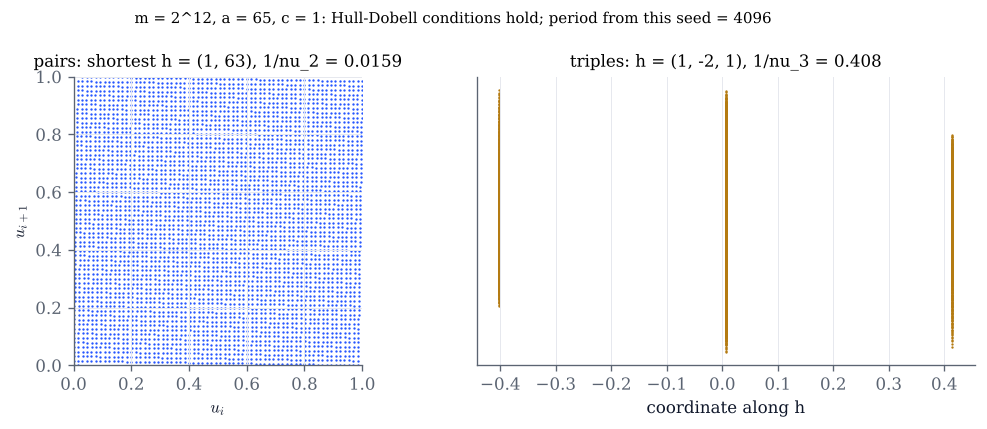

In [2]:
def lcg_lattice(log2_m=12, a=65, c=1, seed=0):
    m = 2**log2_m
    a, c = a % m, c % m
    x = R.lcg_sequence(m + 2, m, a, c, seed % m).astype(float) / m
    P2, P3 = R.tuples(x, 2)[:m], R.tuples(x, 3)[:m]
    h2, nu2 = R.spectral_test(a, m, 2)
    h3, nu3 = R.spectral_test(a, m, 3)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.6))
    ax1.scatter(P2[:, 0], P2[:, 1], s=2, color=COBALT, lw=0)
    ax1.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel="$u_i$", ylabel="$u_{i+1}$",
            title=f"pairs: shortest h = {tuple(int(v) for v in h2)}, 1/nu_2 = {1/nu2:.3g}")
    n = h3 / np.linalg.norm(h3)
    e = np.cross(n, [1.0, 0.0, 0.0]); e /= np.linalg.norm(e)
    ax2.scatter(P3 @ n, P3 @ e, s=2, color=GOLD, lw=0)
    ax2.set(xlabel="coordinate along h", yticks=[],
            title=f"triples: h = {tuple(int(v) for v in h3)}, 1/nu_3 = {1/nu3:.3g}")
    period = R.lcg_period(m, a, c, seed % m)
    fig.suptitle(f"m = 2^{log2_m}, a = {a}, c = {c}: Hull-Dobell conditions "
                 f"{'hold' if R.hull_dobell(m, a, c) else 'fail'}; period from this seed = {period}",
                 fontsize=9)
    fig.tight_layout()
    plt.show()

lcg_lattice()

In [3]:
# Explore: try a = 65, 129, 1025 (multipliers 2^k + 1), then a = 1597 or 3125.
interact(lcg_lattice,
         log2_m=IntSlider(value=12, min=4, max=14, continuous_update=False, description="log2 m"),
         a=IntSlider(value=65, min=1, max=2**14 - 1, continuous_update=False, description="a"),
         c=IntSlider(value=1, min=0, max=99, continuous_update=False, description="c"),
         seed=IntSlider(value=0, min=0, max=99, continuous_update=False, description="seed"));

## 2. Testing a generator

Section 5.2 tests the null hypothesis that the $u_i$ are independent uniforms. Below, uniforms from a
generator of your choice are turned into normals by Box–Muller, and the normals are checked as in the
course's homework: standardised bin counts $(O_j - np_j)/\sigma_j$ with binomial standard deviations,
and the autocorrelations of $z_i$ and $z_i^2$ with the band $\pm 1.96/\sqrt n$. The title reports the
$p$-values of the serial chi-square tests of the uniforms on pairs and on triples (Table 5.1).

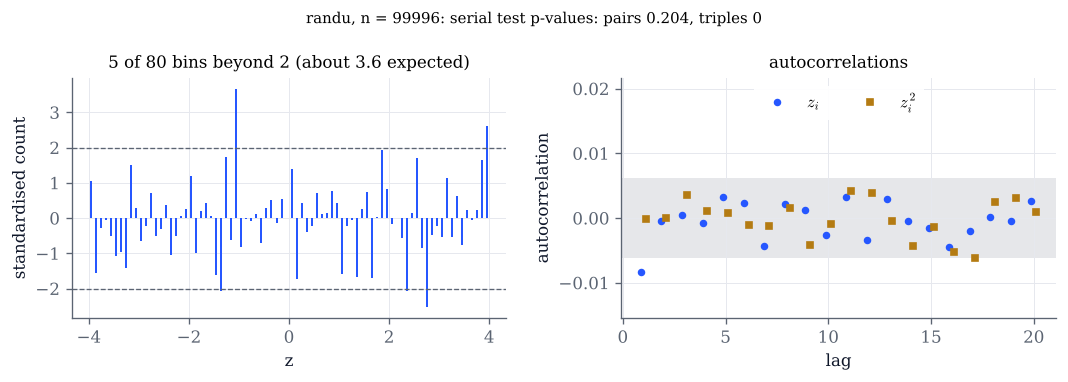

In [4]:
def diagnostics(generator="randu", log10_n=5.0, seed=1):
    n = int(10**log10_n) // 6 * 6
    u = R.uniforms(n, generator, seed=seed)
    z = R.normals_box_muller(u)
    edges = np.round(np.arange(-4.0, 4.0001, 0.1), 10)
    b = R.binned_counts(z, edges, ndtr)
    mid = 0.5 * (edges[1:] + edges[:-1])
    k2 = max(2, min(100, int((n / 2 / 10) ** 0.5)))     # at least ~10 expected per cell
    k3 = max(2, min(20, int((n / 3 / 10) ** (1 / 3))))
    p2 = R.serial_test(u, 2, k2)[1]
    p3 = R.serial_test(u, 3, k3)[1]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
    ax1.vlines(mid, 0, b["z"], color=COBALT, lw=1.2)
    for y in (-2, 2):
        ax1.axhline(y, color=GREY, ls="--", lw=0.8)
    ax1.set(xlabel="z", ylabel="standardised count",
            title=f"{np.sum(np.abs(b['z']) > 2)} of 80 bins beyond 2 (about 3.6 expected)")
    band = 1.96 / math.sqrt(len(z))
    lags = np.arange(1, 21)
    ax2.plot(lags - 0.12, R.autocorrelation(z, 20), "o", ms=3.5, color=COBALT, label="$z_i$")
    ax2.plot(lags + 0.12, R.autocorrelation(z**2, 20), "s", ms=3.5, color=GOLD, label="$z_i^2$")
    ax2.axhspan(-band, band, color=GREY, alpha=0.15, lw=0)
    ax2.set(xlabel="lag", ylabel="autocorrelation", title="autocorrelations",
            ylim=(-2.5 * band, 3.5 * band))
    ax2.legend(loc="upper center", ncol=2, frameon=True, framealpha=0.95, edgecolor="none")
    fig.suptitle(f"{generator}, n = {n}: serial test p-values: pairs {p2:.3g}, triples {p3:.3g}", fontsize=9)
    fig.tight_layout()
    plt.show()

diagnostics()

In [5]:
# Explore: which generator fails which test, and from which sample size on?
interact(diagnostics,
         generator=Dropdown(options=["pcg64", "pcg32", "minstd", "nr32", "randu"], value="randu",
                            description="generator"),
         log10_n=FloatSlider(value=5.0, min=3.0, max=6.0, step=0.25, continuous_update=False,
                             description="log10 n"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 3. Acceptance–rejection for the semicircle law

Example 5.11: the envelope $\chi_\vartheta(x) = \frac{2}{\pi}\min\big(1, (1-|x|\sin\vartheta)/\cos\vartheta\big)$
is the flat level $2/\pi$ cut by the tangents at $\pm\sin\vartheta$. Its acceptance probability is
$p(\vartheta) = \frac{\pi}{4}\frac{1+t}{1+t^2}$ with $t = \tan(\vartheta/2)$ (equation (5.3)). Left: the
envelope and a sample of proposals, kept (cobalt) or rejected (gold). Right: a histogram of the
accepted draws against the density.

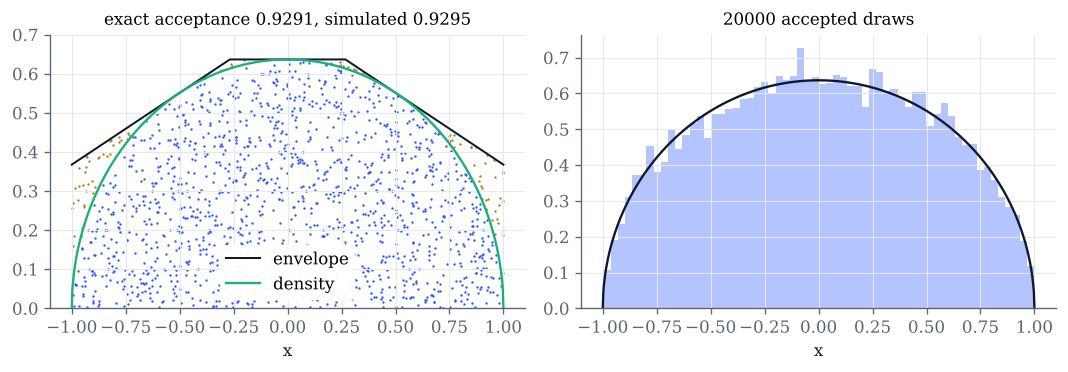

In [6]:
def envelope(theta_deg=30.0, n=20_000, seed=0):
    th = math.radians(theta_deg)
    s, tried = R.semicircle_rejection(n, th, seed=seed)
    rng = np.random.default_rng(seed + 1)
    xs = R._envelope_inverse(rng.random(1500), th)
    ys = rng.random(1500) * R.semicircle_envelope(xs, th)
    keep = ys <= R.semicircle_pdf(xs)
    x = np.linspace(-1, 1, 801)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
    ax1.plot(x, R.semicircle_envelope(x, th), color=INK, lw=1.2, label="envelope")
    ax1.plot(x, R.semicircle_pdf(x), color=GREEN, lw=1.4, label="density")
    ax1.scatter(xs[keep], ys[keep], s=2, color=COBALT, lw=0)
    ax1.scatter(xs[~keep], ys[~keep], s=2, color=GOLD, lw=0)
    ax1.set(xlabel="x", ylim=(0, 0.7),
            title=f"exact acceptance {R.envelope_acceptance(th):.4f}, simulated {n / tried:.4f}")
    ax1.legend(loc="lower center", frameon=True, framealpha=0.95, edgecolor="none")
    ax2.hist(s, bins=60, density=True, color=COBALT, alpha=0.35)
    ax2.plot(x, R.semicircle_pdf(x), color=INK, lw=1.4)
    ax2.set(xlabel="x", title=f"{n} accepted draws")
    fig.tight_layout()
    plt.show()

envelope()

In [7]:
# Explore: the tangent angle theta (0 is the flat envelope), the number of draws and the seed.
interact(envelope,
         theta_deg=FloatSlider(value=30.0, min=0.0, max=89.0, step=1.0, continuous_update=False,
                               description="theta (deg)"),
         n=IntSlider(value=20_000, min=1_000, max=200_000, step=1_000, continuous_update=False,
                     description="draws"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## 4. Box–Muller fed with an LCG

Box–Muller (Proposition 5.12) is exact for independent uniforms. Fed with the consecutive pairs of a small
LCG, it maps the lattice of pairs into spirals (Remark 5.13): every normal lies on a few curves, inside a
circle whose radius $\sqrt{2\log(2m)}$ is set by the resolution. Right: the same number of pairs from PCG64.

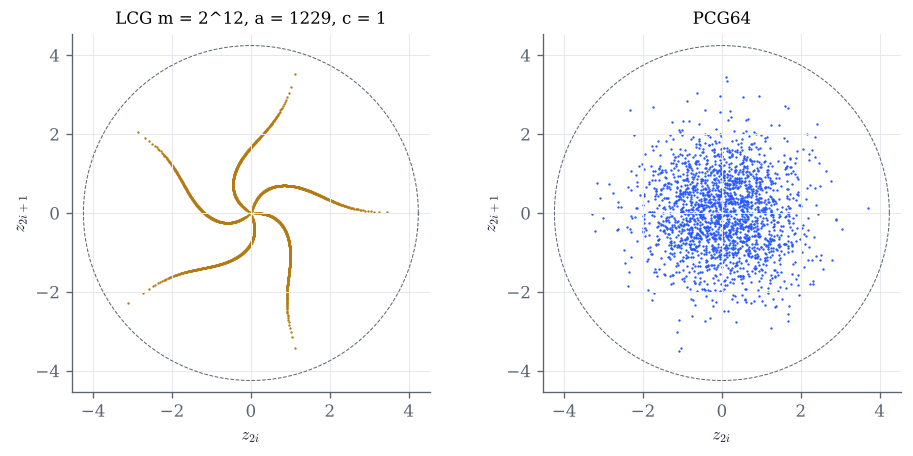

In [8]:
def box_muller_lcg(log2_m=12, a=1229, c=1):
    m = 2**log2_m
    a, c = a % m, c % m
    x = R.lcg_sequence(m + 1, m, a, c, 0).astype(float)
    z = R.normals_box_muller((x[:-1] + 0.5) / m)
    zp = R.normals_box_muller(R.uniforms(m, "pcg64", seed=6))
    t = np.linspace(0, 2 * np.pi, 300)
    rmax = math.sqrt(2 * math.log(2 * m))
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.8))
    for ax, zz, color, title in ((axes[0], z, GOLD, f"LCG m = 2^{log2_m}, a = {a}, c = {c}"),
                                 (axes[1], zp, COBALT, "PCG64")):
        ax.scatter(zz[0::2], zz[1::2], s=2, color=color, lw=0)
        ax.plot(rmax * np.cos(t), rmax * np.sin(t), color=GREY, lw=0.6, ls="--")
        lim = rmax + 0.3
        ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal", title=title,
               xlabel="$z_{2i}$", ylabel="$z_{2i+1}$")
    fig.tight_layout()
    plt.show()

box_muller_lcg()

In [9]:
# Explore: change the multiplier; try c = 0 (a multiplicative generator) with a small a.
interact(box_muller_lcg,
         log2_m=IntSlider(value=12, min=6, max=16, continuous_update=False, description="log2 m"),
         a=IntSlider(value=1229, min=1, max=2**16 - 1, continuous_update=False, description="a"),
         c=IntSlider(value=1, min=0, max=99, continuous_update=False, description="c"));

## 5. Correlated normals: Cholesky and principal components

Proposition 5.14: $\mu + AZ \sim \mathcal N(\mu,\Sigma)$ whenever $AA^\top = \Sigma$. Choose three correlations.
The Cholesky recursion (5.4) either returns the triangular factor or stops at a nonpositive pivot; the
principal components show how much of the total variance each factor carries. The scatter plots use
$5000$ draws built with the principal-components factor.

Cholesky factor:
[[1.    0.    0.   ]
 [0.5   0.866 0.   ]
 [0.3   0.52  0.8  ]]
eigenvalues: [1.944 0.707 0.349]  share of variance: [0.648 0.236 0.116]


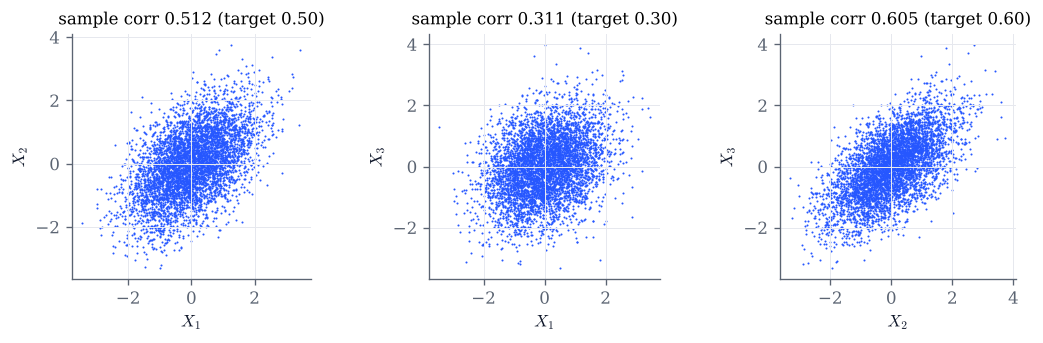

In [10]:
def correlated(rho12=0.5, rho13=0.3, rho23=0.6):
    S = np.array([[1, rho12, rho13], [rho12, 1, rho23], [rho13, rho23, 1]])
    lam = np.sort(np.linalg.eigvalsh(S))[::-1]
    try:
        L = R.cholesky(S)
        msg = "Cholesky factor:\n" + np.array2string(L, precision=3, suppress_small=True)
    except ValueError as err:
        msg = f"Cholesky fails: {err}"
    print(msg)
    print("eigenvalues:", np.round(lam, 3), " share of variance:", np.round(lam / 3, 3))
    if lam[-1] < -1e-12:
        print("Not a covariance matrix: no Gaussian vector has these correlations.")
        return
    X = R.correlated_normals(5000, S, method="pca", seed=0)
    fig, axes = plt.subplots(1, 3, figsize=(9, 2.9))
    for ax, (i, j) in zip(axes, ((0, 1), (0, 2), (1, 2))):
        ax.scatter(X[:, i], X[:, j], s=1.5, color=COBALT, lw=0)
        ax.set(xlabel=f"$X_{i + 1}$", ylabel=f"$X_{j + 1}$", aspect="equal",
               title=f"sample corr {np.corrcoef(X[:, i], X[:, j])[0, 1]:.3f} (target {S[i, j]:.2f})")
    fig.tight_layout()
    plt.show()

correlated()

In [11]:
interact(correlated,
         rho12=FloatSlider(value=0.5, min=-0.99, max=0.99, step=0.01, continuous_update=False, description="ρ12"),
         rho13=FloatSlider(value=0.3, min=-0.99, max=0.99, step=0.01, continuous_update=False, description="ρ13"),
         rho23=FloatSlider(value=0.6, min=-0.99, max=0.99, step=0.01, continuous_update=False, description="ρ23"));

## Things to try

- In section 1, keep $m = 2^{12}$ and compare $a = 65$, $129$ and $1025$. Why are the pairs fine and the
  triples not? Then find a multiplier whose triples look as good as its pairs.
- In section 1, break each Hull–Dobell condition in turn (an even $c$; $a \equiv 3 \pmod 4$) and watch the period.
- In section 2, choose RANDU and lower $n$. From which sample size does the test on triples see the planes?
  Do the histogram and the autocorrelations ever notice?
- In section 3, find the angle that maximises the acceptance probability. Why does the acceptance fall back
  to $\pi/4$ as $\vartheta \to 90°$?
- In section 4, take $c = 0$ and a small multiplier such as $a = 5$. In which directions do the largest normals lie?
- In section 5, set $\rho_{12} = \rho_{13} = 0.95$ and lower $\rho_{23}$ until the factorisation fails.